In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor  
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt


In [6]:
df = pd.read_csv("FY_2025_Hospital_Readmissions_Reduction_Program_Hospital.csv")

In [7]:
print("First few rows of the dataset:")
print(df.head())

First few rows of the dataset:
                     Facility Name  Facility ID State            Measure Name  \
0  SOUTHEAST HEALTH MEDICAL CENTER        10001    AL       READM-30-AMI-HRRP   
1  SOUTHEAST HEALTH MEDICAL CENTER        10001    AL      READM-30-CABG-HRRP   
2  SOUTHEAST HEALTH MEDICAL CENTER        10001    AL        READM-30-HF-HRRP   
3  SOUTHEAST HEALTH MEDICAL CENTER        10001    AL  READM-30-HIP-KNEE-HRRP   
4  SOUTHEAST HEALTH MEDICAL CENTER        10001    AL        READM-30-PN-HRRP   

   Number of Discharges  Footnote  Excess Readmission Ratio  \
0                 296.0       NaN                    0.9483   
1                 151.0       NaN                    0.9509   
2                 681.0       NaN                    1.0597   
3                   NaN       NaN                    0.9654   
4                 490.0       NaN                    0.9715   

   Predicted Readmission Rate  Expected Readmission Rate  \
0                     13.0146              

In [8]:
print("Dataset statistics:")
print(df.describe())

Dataset statistics:
         Facility ID  Number of Discharges     Footnote  \
count   18510.000000           8340.000000  6583.000000   
mean   261770.055105            279.269904     3.187756   
std    164647.739172            266.018069     2.089167   
min     10001.000000              0.000000     1.000000   
25%    110073.000000            115.000000     1.000000   
50%    250048.000000            197.000000     5.000000   
75%    390133.000000            354.000000     5.000000   
max    670327.000000           4501.000000     7.000000   

       Excess Readmission Ratio  Predicted Readmission Rate  \
count              11927.000000                11927.000000   
mean                   1.001719                   14.995386   
std                    0.080547                    5.017854   
min                    0.477900                    1.674200   
25%                    0.956550                   12.533000   
50%                    0.998200                   16.060200   
75%    

In [9]:
# Define target variable FIRST
y = df['Excess Readmission Ratio']

# Remove rows where target is NaN (can't train without labels)
df = df.dropna(subset=['Excess Readmission Ratio'])

# Now redefine X and y after cleaning
y = df['Excess Readmission Ratio']

# Drop unnecessary columns (IDs, names, dates)
X = df.drop(columns=['Facility Name', 'Facility ID', 'Start Date', 'End Date', 'Excess Readmission Ratio'])

In [10]:
# Encode 'State' column
if 'State' in X.columns:
    X['State'] = X['State'].astype('category').cat.codes

# Encode 'Measure Name' column
if 'Measure Name' in X.columns:
    X['Measure Name'] = X['Measure Name'].astype('category').cat.codes


if 'Number of Readmissions' in X.columns:
    X['Number of Readmissions'] = pd.to_numeric(X['Number of Readmissions'], errors='coerce')


# Convert 'Footnote' to numeric if it exists
if 'Footnote' in X.columns:
    X['Footnote'] = pd.to_numeric(X['Footnote'], errors='coerce')


# Convert ALL remaining object columns to numeric
for col in X.columns:
    if X[col].dtype == 'object':
        X[col] = pd.to_numeric(X[col], errors='coerce')



In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [12]:
# Initialize Decision Tree Regressor
dt = DecisionTreeRegressor(
    max_depth=10,           # Maximum depth of the tree
    min_samples_split=5,    # Minimum samples required to split
    min_samples_leaf=2,     # Minimum samples required at leaf node
    random_state=42
)


In [13]:
# Train the model
print("Training the Random Forest model...")
dt.fit(X_train, y_train)
print("Model training completed!\n")


Training the Random Forest model...
Model training completed!



In [14]:
# Make predictions
y_pred = dt.predict(X_test)


In [15]:
# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)


In [16]:
# Print results
print("="*50)
print("MODEL PERFORMANCE METRICS")
print("="*50)
print(f"MAE: {mae:.2f}")
print(f"MSE: {mse:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R²: {r2:.2f}")
print("="*50)
print("\n")

MODEL PERFORMANCE METRICS
MAE: 0.03
MSE: 0.00
RMSE: 0.05
R²: 0.66




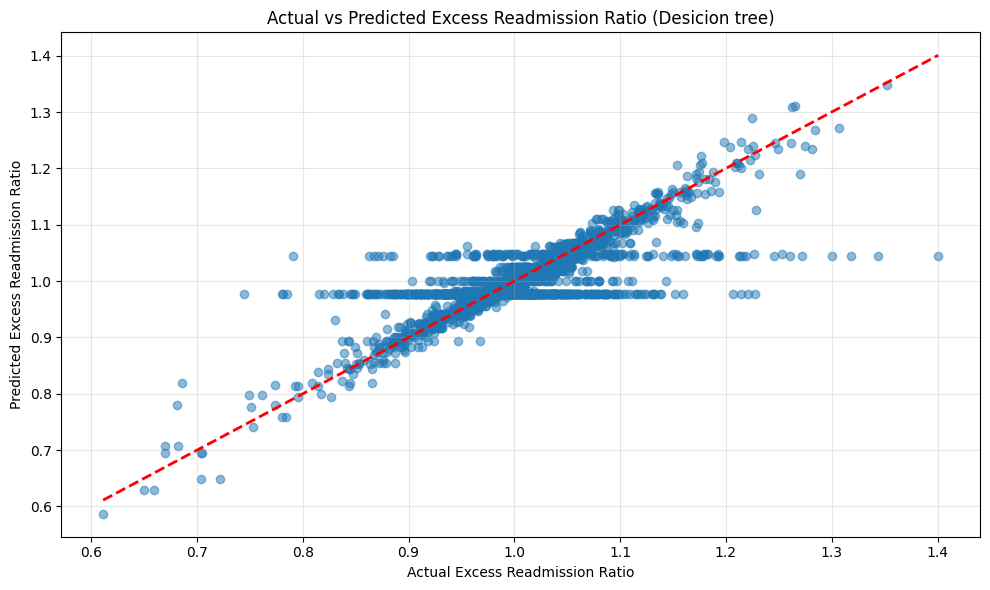

In [18]:
# Optional: Plot Actual vs Predicted
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.xlabel('Actual Excess Readmission Ratio')
plt.ylabel('Predicted Excess Readmission Ratio')
plt.title('Actual vs Predicted Excess Readmission Ratio (Desicion tree)')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()